In [9]:
from google.colab import files
uploaded = files.upload()
for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(name=fn, length=len(uploaded[fn])))

KeyboardInterrupt: 

In [2]:
import os
import zipfile

# 1. فك ضغط الملف
print("Extracting archive...")
with zipfile.ZipFile('/content/archive.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dataset_raw')
print("Extraction complete.")

# 2. استكشاف الهيكل للعثور على مجلدات الصور والملabelات
# أحياناً يكون هناك مجلد إضافي داخل الـ ZIP، لذلك نستكشف أولاً
print("\nDirectory structure:")
for root, dirs, files in os.walk('/content/dataset_raw'):
    level = root.replace('/content/dataset_raw', '').count(os.sep)
    indent = ' ' * 2 * level
    print(indent + os.path.basename(root) + '/')
    if level < 2: # لا نعرض كل الملفات، فقط المجلدات الرئيسية
        for file in files[:3]: # عرض أول 3 ملفات كمثال
            subindent = ' ' * 2 * (level + 1)
            print(subindent + file)


Extracting archive...
Extraction complete.

Directory structure:
dataset_raw/
  archive/
    data/
      labels/
        test/
        train/
        val/
      images/
        test/
        train/
        val/


In [3]:
import os

# Define base path to the extracted dataset
base_path = '/content/dataset_raw/archive/data'

# Define paths for images and labels
image_paths = {
    'train': os.path.join(base_path, 'images', 'train'),
    'val': os.path.join(base_path, 'images', 'val'),
    'test': os.path.join(base_path, 'images', 'test'),
}

label_paths = {
    'train': os.path.join(base_path, 'labels', 'train'),
    'val': os.path.join(base_path, 'labels', 'val'),
    'test': os.path.join(base_path, 'labels', 'test'),
}

# Verify that the paths exist and print a sample
print("Verifying paths and showing samples:")
for key in image_paths:
    print(f"  {key} images path: {image_paths[key]}")
    if os.path.exists(image_paths[key]):
        print(f"    Contains {len(os.listdir(image_paths[key]))} image files.")
    else:
        print(f"    Path does not exist!")

    print(f"  {key} labels path: {label_paths[key]}")
    if os.path.exists(label_paths[key]):
        print(f"    Contains {len(os.listdir(label_paths[key]))} label files.")
    else:
        print(f"    Path does not exist!")

Verifying paths and showing samples:
  train images path: /content/dataset_raw/archive/data/images/train
    Contains 1128 image files.
  train labels path: /content/dataset_raw/archive/data/labels/train
    Contains 1142 label files.
  val images path: /content/dataset_raw/archive/data/images/val
    Contains 143 image files.
  val labels path: /content/dataset_raw/archive/data/labels/val
    Contains 143 label files.
  test images path: /content/dataset_raw/archive/data/images/test
    Contains 141 image files.
  test labels path: /content/dataset_raw/archive/data/labels/test
    Contains 141 label files.


## عرض عينة من البيانات
دعنا نختار صورة عشوائية وملف التصنيف الخاص بها من مجموعة التدريب لعرضها وفهم هيكلها.

Viewing sample image: /content/dataset_raw/archive/data/images/train/image732.jpg
Corresponding label file: /content/dataset_raw/archive/data/labels/train/image732.txt


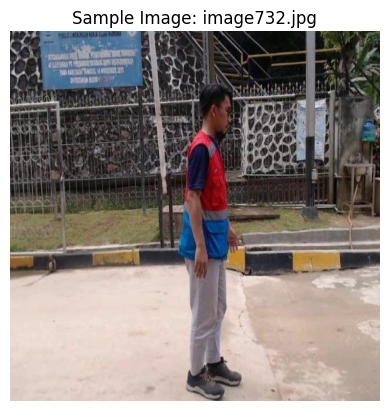


Label Content:
3 0.527789 0.949594 0.127578 0.100812
2 0.528820 0.450633 0.166672 0.349797
3 0.580156 0.924805 0.117500 0.084578
6 0.540172 0.546133 0.251844 0.907734



In [5]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Get a list of all image files in the training set
train_image_files = [f for f in os.listdir(image_paths['train']) if f.endswith(('.jpg', '.jpeg', '.png', '.gif'))]

# Pick a random image file
if train_image_files:
    random_image_filename = random.choice(train_image_files)
    random_image_path = os.path.join(image_paths['train'], random_image_filename)

    # Corresponding label filename (assuming .txt extension and same base name)
    label_filename = os.path.splitext(random_image_filename)[0] + '.txt'
    random_label_path = os.path.join(label_paths['train'], label_filename)

    print(f"Viewing sample image: {random_image_path}")
    print(f"Corresponding label file: {random_label_path}")

    # Load and display the image
    try:
        img = Image.open(random_image_path)
        plt.imshow(img)
        plt.title(f"Sample Image: {random_image_filename}")
        plt.axis('off') # Hide axes ticks
        plt.show()
    except Exception as e:
        print(f"Could not load image {random_image_filename}: {e}")

    # Read and print the content of the label file
    if os.path.exists(random_label_path):
        with open(random_label_path, 'r') as f:
            label_content = f.read()
        print("\nLabel Content:")
        print(label_content)
    else:
        print("\nLabel file not found for this image.")
else:
    print("No image files found in the training set.")

# Placeholder for class names (you will need to fill this based on your dataset documentation)
# class_names = ['class1', 'class2', 'class3', ...]
# print(f"\nExpected Class Names (placeholder): {class_names}")

## إعداد بيئة التدريب وتحديد الفئات
سنقوم بتثبيت مكتبة `ultralytics`، ثم إعداد ملف `data.yaml` الذي سيحتِّوي على مسارات البيانات وأسماء الفئات (classes).

In [6]:
# تثبيت مكتبة ultralytics
!pip install ultralytics -qq

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 10.3 MB/s eta 0:00:00


In [7]:
# إنشاء ملف data.yaml لتعريف مسارات البيانات والفئات
# **ملاحظة: تحتاج إلى تحديث أسماء الفئات (names) لتتوافق مع مجموعة بياناتك الفعلية.**

# تحديد المسارات المطلقة لصور التدريب والتحقق والاختبار
train_images_dir = image_paths['train']
val_images_dir = image_paths['val']
test_images_dir = image_paths['test']

# افتراض أن ملفات التسميات (labels) موجودة في نفس هيكل المجلدات
# ولكن داخل مجلد 'labels' بدلاً من 'images'

data_yaml_content = f"""
path: {base_path}  # Base path to dataset
train: images/train    # train images relative to path
val: images/val      # val images relative to path
test: images/test     # test images relative to path (optional)

# number of classes
nc: 7 # Based on the max class ID '6' found in the sample label + 1 (assuming 0-indexed classes)

# class names
names:
  0: 'class_0'
  1: 'class_1'
  2: 'class_2' # Based on sample label
  3: 'class_3' # Based on sample label
  4: 'class_4'
  5: 'class_5'
  6: 'class_6' # Based on sample label
"""

# حفظ ملف data.yaml في مجلد العمل الحالي
with open('data.yaml', 'w') as f:
    f.write(data_yaml_content)

print("data.yaml file created successfully.")
print("\nContent of data.yaml:")
!cat data.yaml

data.yaml file created successfully.

Content of data.yaml:

path: /content/dataset_raw/archive/data  # Base path to dataset
train: images/train    # train images relative to path
val: images/val      # val images relative to path
test: images/test     # test images relative to path (optional)

# number of classes
nc: 7 # Based on the max class ID '6' found in the sample label + 1 (assuming 0-indexed classes)

# class names
names:
  0: 'class_0'
  1: 'class_1'
  2: 'class_2' # Based on sample label
  3: 'class_3' # Based on sample label
  4: 'class_4'
  5: 'class_5'
  6: 'class_6' # Based on sample label


## تحميل النموذج والتدريب
الآن سنقوم بتحميل نموذج YOLOv8nan (yolov8n.pt) وبدء التدريب باستخدام ملف `data.yaml` الذي أنشأناه.

In [10]:
from ultralytics import YOLO

# تحميل نموذج YOLOv8n المدرب مسبقًا (يمكنك اختيار نماذج أخرى مثل yolov8s.pt, yolov8m.pt)
model = YOLO('yolov8n.pt')  # 'n' for nano, 's' for small, 'm' for medium etc.

print("YOLOv8 model loaded successfully.")

# بدء التدريب
# **ملاحظة: يمكنك تعديل عدد العصور (epochs) وحجم الدفعة (batch) حسب الحاجة.**
results = model.train(data='data.yaml', epochs=25, imgsz=640, batch=16, name='yolov8_custom_dataset')

print("Training complete.")

YOLOv8 model loaded successfully.
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_custom_dataset-2, nbs=64, nms=None, ops